# Лабораторная работа №4 — задание 3

Реализуем субдифференциалы для

$$
\|x\|_2,\qquad \|x\|_1,\qquad \max_i x_i,
$$

а затем проверим субдифференциальное условие

$$
\langle a,x-x^*\rangle\ge0
\qquad \forall x\in X.
$$

In [1]:
import itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

TOL = 1e-10

Для выпуклой функции $f$ в точке $x$ вектор $g$ является субградиентом, если

$$
f(y)\ge f(x)+g^T(y-x)
\qquad \forall y.
$$

Множество всех таких векторов обозначается $\partial f(x)$.

In [2]:
def subdiff_norm(x, tol=TOL):
    """
    Представители ∂||x||_2.
    При x != 0 субградиент единственный.
    При x = 0 возвращаются представители единичного шара.
    """
    x = np.asarray(x, dtype=float)
    norm_x = np.linalg.norm(x)

    if norm_x > tol:
        return np.array([x / norm_x])

    n = x.size
    return np.vstack((np.zeros(n), np.eye(n), -np.eye(n)))


def subdiff_l1(x, tol=TOL):
    """
    Представители ∂||x||_1.
    В нулевых координатах берём значения -1, 0, 1.
    """
    x = np.asarray(x, dtype=float)
    signs = np.sign(x)
    zero_indices = np.flatnonzero(np.abs(x) <= tol)

    choices = list(itertools.product((-1.0, 0.0, 1.0),
                                      repeat=len(zero_indices)))

    representatives = []
    for choice in choices:
        g = signs.copy()
        g[zero_indices] = choice
        representatives.append(g)

    return np.array(representatives)


def subdiff_max(x, tol=TOL):
    """
    Представители ∂ max_i x_i.
    Точное множество — выпуклая оболочка базисных векторов
    с индексами максимальных координат.
    """
    x = np.asarray(x, dtype=float)
    active = np.flatnonzero(
        np.isclose(x, np.max(x), atol=tol, rtol=0)
    )

    basis = np.eye(x.size)[active]
    average = basis.mean(axis=0)

    return np.vstack((basis, average))

Проверим формулы на дифференцируемых и недифференцируемых точках.

In [3]:
print("∂||x||_2 в x=(3,4):")
print(subdiff_norm(np.array([3.0, 4.0])))

print("\nПредставители ∂||x||_2 в x=0:")
print(subdiff_norm(np.zeros(2)))

print("\nПредставители ∂||x||_1 в x=(0,2):")
print(subdiff_l1(np.array([0.0, 2.0])))

print("\nПредставители ∂max в x=(2,2,1):")
print(subdiff_max(np.array([2.0, 2.0, 1.0])))

∂||x||_2 в x=(3,4):
[[0.6 0.8]]

Представители ∂||x||_2 в x=0:
[[ 0.  0.]
 [ 1.  0.]
 [ 0.  1.]
 [-1. -0.]
 [-0. -1.]]

Представители ∂||x||_1 в x=(0,2):
[[-1.  1.]
 [ 0.  1.]
 [ 1.  1.]]

Представители ∂max в x=(2,2,1):
[[1.  0.  0. ]
 [0.  1.  0. ]
 [0.5 0.5 0. ]]


## Задача 3.2

Рассматриваем

$$
\|x\|_2-\langle c,x\rangle\to\min.
$$

Из неравенства Коши:

- если $\|c\|<1$, единственный минимум $x^*=0$;
- если $\|c\|=1$, минимумы имеют вид $x^*=tc$, $t\ge0$;
- если $\|c\|>1$, задача не ограничена снизу.

In [4]:
def norm_linear_objective(x, c):
    return np.linalg.norm(x) - np.dot(c, x)


c_cases = {
    "||c|| < 1": 0.5 * np.array([1.0, 0.0]),
    "||c|| = 1": np.array([1.0, 0.0]),
    "||c|| > 1": 1.5 * np.array([1.0, 0.0]),
}

for name, c in c_cases.items():
    print(name)
    print("c =", c, "norm(c) =", np.linalg.norm(c))

    if np.linalg.norm(c) > 1:
        print("Задача не ограничена снизу; численный минимум не существует.")
        print()
        continue

    result = minimize(
        norm_linear_objective,
        x0=np.array([0.2, 0.3]),
        args=(c,),
        method="Powell",
        bounds=[(-10.0, 10.0)] * 2,
        options={"maxiter": 1000}
    )

    print("SciPy:", result.x, "f =", result.fun)
    print()

||c|| < 1
c = [0.5 0. ] norm(c) = 0.5
SciPy: [2.32735126e-05 1.49880108e-15] f = 1.1636756314142687e-05

||c|| = 1
c = [1. 0.] norm(c) = 1.0
SciPy: [9.99148691e+00 6.79903132e-08] f = 0.0

||c|| > 1
c = [1.5 0. ] norm(c) = 1.5
Задача не ограничена снизу; численный минимум не существует.



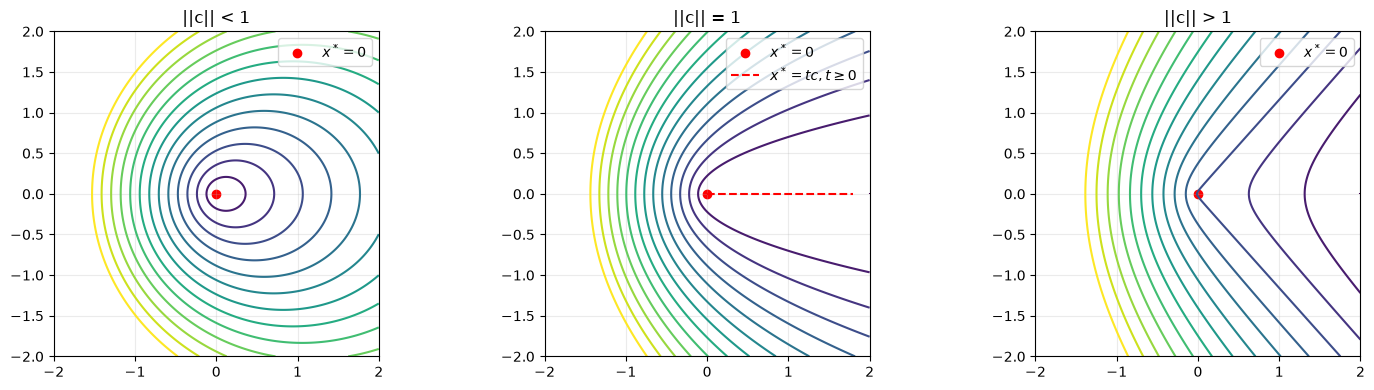

In [5]:
grid = np.linspace(-2.0, 2.0, 400)
XX, YY = np.meshgrid(grid, grid)
points = np.stack((XX, YY), axis=-1)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, c) in zip(axes, c_cases.items()):
    values = np.linalg.norm(points, axis=-1) - points @ c
    levels = np.linspace(np.min(values), np.percentile(values, 80), 14)

    ax.contour(XX, YY, values, levels=levels)
    ax.scatter(0, 0, color="red", label="$x^*=0$")

    if np.isclose(np.linalg.norm(c), 1):
        t = np.linspace(0, 1.8, 100)
        ax.plot(t * c[0], t * c[1], "r--",
                label=r"$x^*=tc, t\geq0$")

    ax.set_title(name)
    ax.set_aspect("equal")
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

## Задача 3.3

Рассматриваем

$$
\|x\|_1\to\min,
\qquad x\ge b.
$$

Аналитически:

$$
\boxed{x^*=\max(b,0)}
$$

покоординатно.

Подходящий субградиент:

$$
a_j=
\begin{cases}
1,&b_j\ge0,\\
0,&b_j<0.
\end{cases}
$$

Он удовлетворяет $a\in\partial\|x^*\|_1$ и условию

$$
a^T(x-x^*)\ge0
\qquad \forall x\ge b.
$$

In [6]:
def l1_objective(x):
    return np.sum(np.abs(x))


def l1_subgradient_at_solution(x_star, b, tol=TOL):
    # Если x*_j > 0, берём a_j=1.
    # Если b_j < 0 и x*_j=0, берём a_j=0.
    return np.where(b >= -tol, 1.0, 0.0)


rng = np.random.default_rng(7)
b = rng.uniform(-2.0, 2.0, size=8)

x_star = np.maximum(b, 0.0)
a = l1_subgradient_at_solution(x_star, b)

print("b      =", b)
print("x_star =", x_star)
print("a      =", a)

# Проверяем a ∈ ∂||x*||_1
print("Субградиентная проверка:",
      np.all(np.isin(a, (-1.0, 0.0, 1.0))))
print("Условие (1.14) выполняется покоординатно для x >= b.")

result = minimize(
    l1_objective,
    x0=np.maximum(b, 1.0),
    method="L-BFGS-B",
    bounds=[(bi, None) for bi in b],
    options={"ftol": 1e-12, "gtol": 1e-10}
)

print("\nSciPy:")
print("x =", result.x)
print("error =", np.linalg.norm(result.x - x_star))

b      = [ 0.50038187  1.5888552   1.10274276 -1.09917124 -0.79933486  1.49421378
 -1.97893878  1.28491367]
x_star = [0.50038187 1.5888552  1.10274276 0.         0.         1.49421378
 0.         1.28491367]
a      = [1. 1. 1. 0. 0. 1. 0. 1.]
Субградиентная проверка: True
Условие (1.14) выполняется покоординатно для x >= b.

SciPy:
x = [ 5.00381866e-01  1.58885520e+00  1.10274276e+00 -3.86268870e-09
 -3.86268870e-09  1.49421378e+00 -3.86268870e-09  1.28491367e+00]
error = 6.690373075434673e-09


## Проекционный субградиентный метод

Для $f(x)=\|x\|_1$ берём $g_k=\operatorname{sign}(x_k)$, а проекция на множество $x\ge b$ имеет простой вид:

$$
P_X(y)=\max(y,b).
$$

Субградиентный метод:
x = [ 5.00381866e-01  1.58885520e+00  1.10274276e+00 -2.43736676e-09
 -2.43736676e-09  1.49421378e+00 -2.43736676e-09  1.28491367e+00]
error = 4.221643070681419e-09


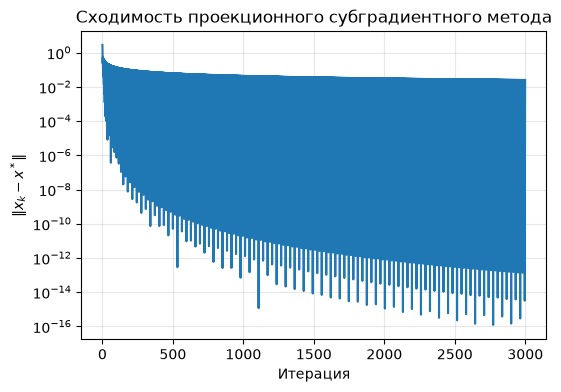

In [7]:
def projected_subgradient_l1(b, iterations=3000, step0=0.8):
    x = np.maximum(b, 1.5)
    history = []

    for k in range(iterations):
        history.append(np.linalg.norm(x - np.maximum(b, 0.0)))

        g = np.sign(x)
        step = step0 / np.sqrt(k + 1)

        x = np.maximum(x - step * g, b)

    return x, np.array(history)


x_sg, history = projected_subgradient_l1(b)

print("Субградиентный метод:")
print("x =", x_sg)
print("error =", np.linalg.norm(x_sg - x_star))

plt.figure(figsize=(6, 4))
plt.semilogy(history + 1e-16)
plt.xlabel("Итерация")
plt.ylabel(r"$\|x_k-x^*\|$")
plt.title("Сходимость проекционного субградиентного метода")
plt.grid(alpha=0.3)
plt.show()